In [19]:
import numpy as np
import matplotlib.pyplot as plt
import time
import cv2

## Huỳnh Nam – Demo 2: Toán tử điểm

Hàm

In [20]:
def IShow(*I,T = None):
    n = len(I)
    f, ax = plt.subplots(1, n, figsize=(2 * n, 2))
    if n == 1:
        ax = [ax]
    for i, (a, Im) in enumerate(zip(ax, I)):
        a.imshow(Im.astype(np.uint8),cmap='gray',vmin=0,vmax=255)
        a.axis('off')  
        if T is not None:
            a.set_title(T[i], fontsize=9)        
    plt.tight_layout()
    plt.show()
def LShow(*I,T = None):
    n = len(I)
    f, ax = plt.subplots(1, n, figsize=(2 * n, 2))
    if n == 1:
        ax = [ax]
    for i, (a, Im) in enumerate(zip(ax, I)):
        a.bar(range(256), Hist(Im), width=1, color='k')  
        if T is not None:
            a.set_title(T[i], fontsize=9)        
    plt.tight_layout()
    plt.show()  
def LnrOp(I, A, B):
    G = A*I.astype(float)+B
    return np.clip(G,0,255).astype(np.uint8)

def GmaCorc(I,Gma):
    G = ((I.astype(float)/255)**Gma)*255
    return G.astype(np.uint8)

def Hist(K):
    return np.bincount(K.ravel(),minlength=256).astype(np.uint8)
def LUT(H):
    CDF = H.cumsum()
    CDF_Min = CDF[CDF > 0].min()
    return (((CDF-CDF_Min)/(CDF[-1]-CDF_Min))*255).astype(np.uint8)
def EqHist(I):
    H = Hist(I)
    G= LUT(H)[I]
    return G.astype(np.uint8)
def Blnr(Q11, Q21, Q12, Q22, dx, dy):
    R1 = (1 - dx) * Q11 + dx * Q21
    R2 = (1 - dx) * Q12 + dx * Q22
    return (1 - dy) * R1 + dy * R2

Nguồn :
https://github.com/opencv/opencv/blob/5.x/samples/data/home.jpg 
https://github.com/opencv/opencv/blob/5.x/samples/data/sudoku.png
https://github.com/opencv/opencv/blob/5.x/samples/data/orange.jpg

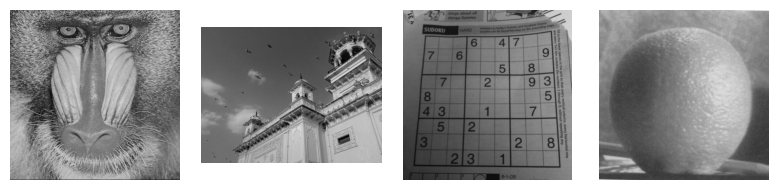

In [21]:
I = cv2.imread("../images/baboon.jpg", cv2.IMREAD_GRAYSCALE)
Home = cv2.imread("../images/home.jpg", cv2.IMREAD_GRAYSCALE)
Sudoku = cv2.imread("../images/sudoku.png", cv2.IMREAD_GRAYSCALE)
Orange = cv2.imread("../images/orange.jpg", cv2.IMREAD_GRAYSCALE)
IShow(I,Home,Sudoku,Orange)

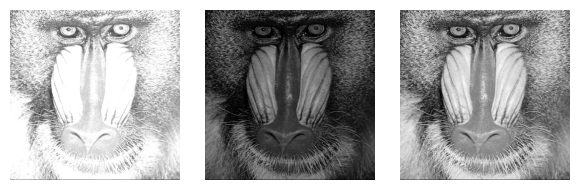

In [22]:
IShow(LnrOp(I,1.5,40),GmaCorc(I,2.2),EqHist(I))

## KT1 – CLAHE: hàm

In [23]:
def Climit(I,S,Gr=(8,8)):
    L=256
    H,W = I.shape
    N = (-(-H // Gr[0])) * (-(-W // Gr[1]))
    return S * N / L

def clip_histogram(hist, clip_limit):
    B = clip_limit
    H = hist
    L = 256
    E = np.maximum(H-B,0)
    H = np.minimum(H,B)
    E_T = E.sum()
    H = H + (E_T / L)
    return H

def build_tile_luts(img, grid=(8, 8), clip_limit=2.0):
    I = img
    Gy,Gx= grid
    L = 256
    h,w = I.shape
    Th = -(-h//Gy) 
    Tw = -(-w//Gx)
    pad = np.pad(I, ((0, Gy * Th - h), (0, Gx * Tw - w)), mode='reflect')
    n_tile =Th*Tw
    B = Climit(I,clip_limit,grid)
    T = np.empty((Gy, Gx, L), dtype=np.uint8)
    for i in range(Gy):
        for j in range(Gx):
            tile = pad[i * Th:(i + 1) * Th, j * Tw:(j + 1) * Tw]
            H = clip_histogram(Hist(tile),B)
            lut = (L - 1) / n_tile * np.cumsum(H)
            T[i, j] = np.clip(np.round(lut), 0, L - 1).astype(np.uint8)
    return T
def clahe(img, grid=(8, 8), clip_limit=2.0):
    I=img
    Gy, Gx = grid
    T = build_tile_luts(I, grid, clip_limit)
    h, w = img.shape
    Th, Tw = -(-h // Gy), -(-w // Gx) 
    fy = np.clip((np.arange(h) + 0.5) / Th - 0.5, 0, Gy - 1)
    fx = np.clip((np.arange(w) + 0.5) / Tw - 0.5, 0, Gx - 1)
    i0 = np.floor(fy).astype(int); i1 = np.minimum(i0 + 1, Gy - 1)
    j0 = np.floor(fx).astype(int); j1 = np.minimum(j0 + 1, Gx - 1)
    b = (fy - i0)[:, None]
    a = (fx - j0)[None, :]

    I0, I1 = i0[:, None], i1[:, None]
    J0, J1 = j0[None, :], j1[None, :]
    Q11, Q21 = T[I0, J0, I], T[I0, J1, I]
    Q12, Q22 = T[I1, J0, I], T[I1, J1, I] 
    G = Blnr(Q11, Q21, Q12, Q22, a, b)
    return np.clip(np.round(G),0,255).astype(np.uint8)
    

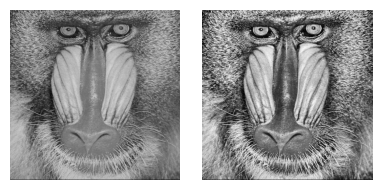

In [24]:
IShow(I,clahe(I,(8,8),2))

## KT1 – CLAHE: thí nghiệm

### Có dùng AI hỗ trợ
Công cụ: Claude (Anthropic), mô hình Claude Opus 5.5, qua claude.ai
Mục đích: chọn ảnh thử phù hợp, chọn tham số

Prompt:
> chọn ảnh để clahe thắng và thua
> chọn tham số như thế nào ?
Đã sửa lại những gì: Sửa lại gamma để trông nó làm rõ sáng tối hơn

a


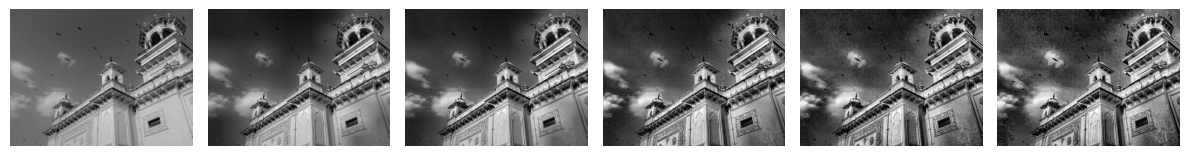

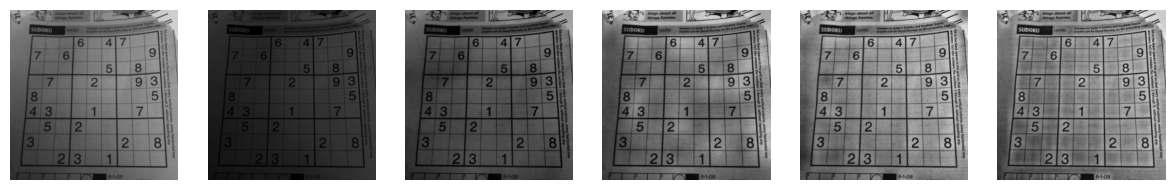

b
Với ảnh Clahe thẳng


C:\Users\msayt\AppData\Local\Temp\ipykernel_67996\2515042788.py:37: RuntimeWarning: invalid value encountered in cast
  return (((CDF-CDF_Min)/(CDF[-1]-CDF_Min))*255).astype(np.uint8)


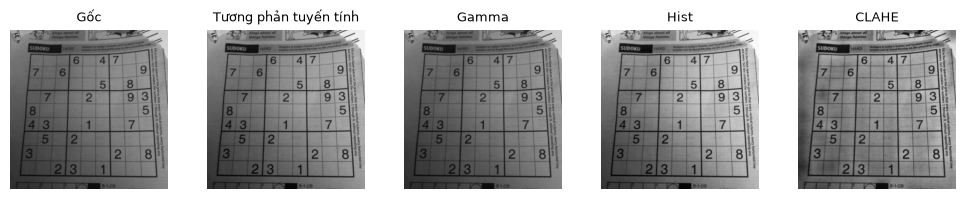

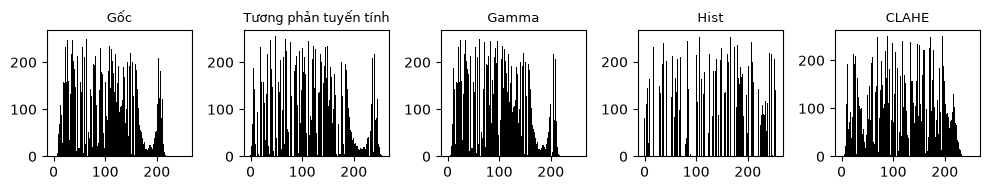

Với CLAHE thua


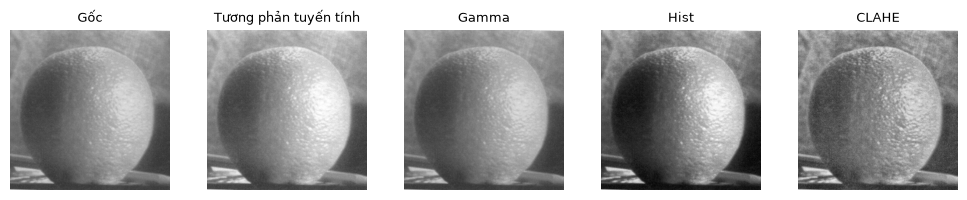

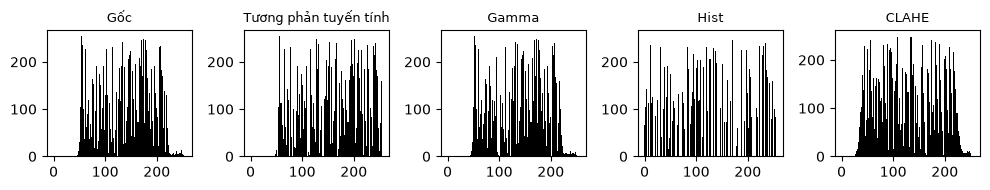

In [31]:
"""A """
print("a")
IShow(Home,*[clahe(Home, (8, 8), s) for s in [1, 2, 5, 10, 20]])
IShow(Sudoku, *[clahe(Sudoku, g, 2)   for g in [(2, 2), (4, 4), (8, 8), (16, 16),(32, 32)]])
"""B"""
print("b")
print("Với ảnh Clahe thẳng")
Title = ['Gốc','Tương phản tuyến tính','Gamma','Hist','CLAHE']
lo, hi = Sudoku.min(), Sudoku.max() 
A = 255 / (hi - lo); B = -A * lo          
Gma = np.log(0.4) / np.log(np.median(Sudoku) / 255) 
Img = Sudoku
IShow(Img,LnrOp(Img,A,B),GmaCorc(Img,Gma),EqHist(Img),clahe(Img,(16, 16),1.5),T = Title)
LShow(Img,LnrOp(Img,A,B),GmaCorc(Img,Gma),EqHist(Img),clahe(Img,(16, 16),1.5),T = Title)
print("Với CLAHE thua")
Img = Orange
IShow(Img,LnrOp(Img,A,B),GmaCorc(Img,Gma),EqHist(Img),clahe(Img,(16, 16),1.5),T = Title)
LShow(Img,LnrOp(Img,A,B),GmaCorc(Img,Gma),EqHist(Img),clahe(Img,(16, 16),1.5),T = Title)
